# Heuristic decision-making

Which of two cities is larger? People often answer such a question with a
simple rule, a heuristic. Some people look at the single best cue. Other
people weigh all cues. The stopping model of Lee & Wagenmakers (2013,
chapter 18.2) finds out which rule each person uses. This case study takes
the PyMC version of the model and uses it in `elicito` with the PyMC
adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Two simulated experts give their knowledge about the
   choices of the participants. `elicito` learns a prior from each expert.
   PyMC then fits the model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.021.
- The translated model draws 10 000 samples about 10 times faster than
  PyMC.
- The quantities of one participant tell `elicito` only the mean of the
  share of TTB users, not its uncertainty. A quantity of the group, the
  share of TTB majorities, adds the uncertainty.
- The elicited quantiles agree with the quantiles of both experts. For
  the group quantity, the elicited quantiles are wider than those of the
  experts.
- The two experts disagree strongly about the share of TTB users: a mean
  of 0.84 against 0.15. The posterior means differ less: 0.53 against
  0.36. The 20 participants of the data dominate the elicited priors.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import io, stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

SEED = tf.constant([2013, 18], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging
import warnings

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)
# R-hat of an indicator zi that never changes is 0 / 0
warnings.filterwarnings("ignore", message="invalid value encountered in scalar divide")

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The city task

In each of 30 questions, a participant sees two German cities and chooses
the larger one. Nine binary cues describe each city, for example "has a
university" or "is a state capital". Each cue has a validity: the share of
city pairs in which the cue points to the larger city.

Two heuristics decide the question from the cues:

- **Take-the-best (TTB)** looks at the cues in the order of their
  validity. It stops at the first cue that differs between the two cities,
  and chooses with this cue.
- **Weighted additive (WADD)** adds the weighted cues of each city. It
  chooses the city with the larger sum.

In 24 questions, the two heuristics choose the same city. In the other 6
questions, the **conflict questions**, they choose different cities. Only
the conflict questions show which heuristic a participant uses. The data
are the 30 choices of 20 participants.

In [4]:
matdata = io.loadmat("data/StopSearchData.mat")
y = np.squeeze(matdata["y"])  # 1 if the participant chooses the first city
m = np.squeeze(np.float32(matdata["m"]))  # 9 cues of each of 83 cities
p = np.squeeze(matdata["p"])  # the two cities of each question
v = np.squeeze(np.float32(matdata["v"]))  # validity of each cue
x = np.squeeze(np.float32(matdata["x"]))  # WADD weight of each cue
ns, nq = y.shape  # participants and questions

# the cue differences of each question, first city minus second city
qcc = m[p[:, 0] - 1] - m[p[:, 1] - 1]


def code(score: Any) -> Any:
    """Code a decision: 0 for the second city, 1 for a guess, 2 for the first"""
    return -1 * (score < 0) + (score > 0) + 1


TTB_CODE = code(np.sum(qcc * 2.0 ** np.argsort(v), axis=1))
WADD_CODE = code(np.sum(qcc * x, axis=1))
CONFLICT = TTB_CODE != WADD_CODE

# TTB chooses the first city in all questions: a TTB choice is y = 1
FIRST_CITY = 2  # the code of a choice of the first city
assert (TTB_CODE == FIRST_CITY).all()

ttb_conflict_obs = y[:, CONFLICT].mean(axis=1)
ttb_agree_obs = y[:, ~CONFLICT].mean(axis=1)

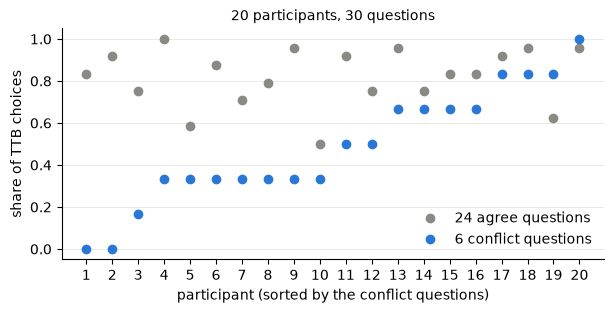

In [5]:
order = np.argsort(ttb_conflict_obs, kind="stable")
participants = np.arange(1, ns + 1)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(
    participants,
    ttb_agree_obs[order],
    "o",
    color=GREY,
    label=f"{(~CONFLICT).sum()} agree questions",
)
ax.plot(
    participants,
    ttb_conflict_obs[order],
    "o",
    color=BLUE,
    label=f"{CONFLICT.sum()} conflict questions",
)
ax.set(
    xlabel="participant (sorted by the conflict questions)",
    ylabel="share of TTB choices",
    xticks=participants,
    ylim=(-0.05, 1.05),
    title=f"{ns} participants, {nq} questions",
)
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right")
plt.show()

The participants form two groups. Participants 1 to 10 make at most 2
TTB choices in the 6 conflict questions. Participants 13 to 20 make at
least 4. On the agree questions, most participants make more than 70 % TTB
choices.

## The model

The model has two kinds of parameters:

- $z_i$ (`zi`) is 1 if participant $i$ uses TTB, and 0 if the participant
  uses WADD. $\phi$ (`phi`) is the **share of TTB users**:
  $z_i \sim \operatorname{Bernoulli}(\phi)$.
- $\gamma$ (`gamma`) is the **accuracy**: the probability that a
  participant follows the decision of the heuristic.

If the heuristic chooses the first city, the participant chooses it with
probability $\gamma$. If the heuristic chooses the second city, the
participant chooses the first city with probability $1 - \gamma$. The
choice $y_{iq}$ is 1 if participant $i$ chooses the first city in question
$q$:

$$y_{iq} \sim \operatorname{Bernoulli}(\theta_{iq}), \qquad
\phi \sim \operatorname{Beta}(1, 1), \qquad
\gamma \sim \operatorname{Uniform}(0.5, 1).$$

The PyMC model follows the rules of [Use a PyMC model][use-a-pymc-model]:
each input of a prior is a named `pm.Data` node. The indicators $z_i$
have no `pm.Data` input, so the translated model samples them.

In [6]:
TMAT = np.tile(TTB_CODE, (ns, 1))  # the TTB code of each participant
WMAT = np.tile(WADD_CODE, (ns, 1))  # and question

with pm.Model() as model:
    phi = pm.Beta("phi", alpha=pm.Data("phi_alpha", 1.0), beta=pm.Data("phi_beta", 1.0))
    gamma = pm.Uniform(
        "gamma", lower=pm.Data("gamma_lower", 0.5), upper=pm.Data("gamma_upper", 1.0)
    )

    # the heuristic of each participant: 1 for TTB, 0 for WADD
    zi = pm.Bernoulli("zi", p=phi, shape=ns)
    codes = pm.math.switch(pm.math.eq(zi[:, None], 1), TMAT, WMAT)

    # the probability to choose the first city, for the codes 0, 1 and 2
    theta = pm.math.stack([1 - gamma, 0.5, gamma])
    pm.Bernoulli("yiq", p=theta[codes], observed=y)

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads.
`adapter_pymc.model` returns the translated model. It returns each
observed variable and each `pm.Deterministic` by name: here `yiq`.

In [7]:
print([(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model)])

generative_model = adapter_pymc.model(model)()

[('phi', 'Beta'), ('gamma', 'Uniform')]


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. We compare three outputs:

- `yiq`, the 600 choices. The table shows the largest $D$.
- the share of TTB choices on the 6 conflict questions, for each
  participant,
- the share of TTB choices on the 24 agree questions, for each
  participant.

For the two shares, the table shows the largest $D$ of the 20
participants.

In [8]:
def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw(model["yiq"], draws=DRAWS, random_seed=1)

choices = {
    "TensorFlow": np.asarray(tf_out["yiq"][0], dtype=float),
    "PyMC": np.asarray(pm_out, dtype=float),
}
samples = {
    "yiq": {label: c.reshape(DRAWS, -1) for label, c in choices.items()},
    "TTB, conflict": {
        label: c[..., CONFLICT].mean(axis=-1) for label, c in choices.items()
    },
    "TTB, agree": {
        label: c[..., ~CONFLICT].mean(axis=-1) for label, c in choices.items()
    },
}
distance = {
    name: max(
        stats.ks_2samp(
            pair["TensorFlow"][:, j], pair["PyMC"][:, j], method="asymp"
        ).statistic
        for j in range(pair["PyMC"].shape[1])
    )
    for name, pair in samples.items()
}

print(f"{'output':<16}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for name, pair in samples.items():
    tf_stats, pm_stats = (
        f"{values.mean():.2f}, {values.std():.2f}" for values in pair.values()
    )
    print(f"{name:<16}{tf_stats:>22}{pm_stats:>18}{distance[name]:>8.3f}")
assert max(distance.values()) < TOL

output             TensorFlow mean, sd     PyMC mean, sd       D
yiq                         0.70, 0.46        0.70, 0.46   0.021
TTB, conflict               0.50, 0.33        0.50, 0.33   0.015
TTB, agree                  0.75, 0.17        0.75, 0.17   0.011


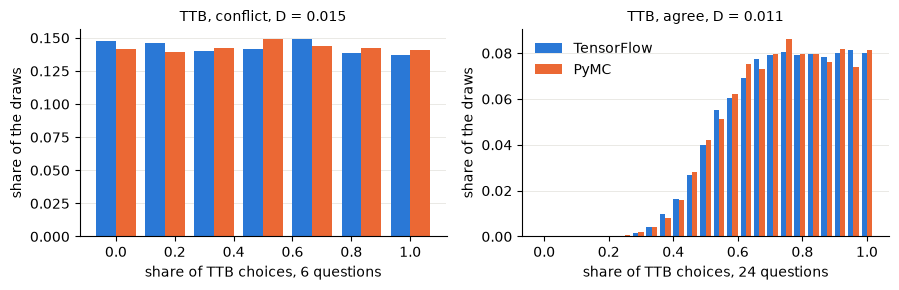

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
for ax, name in zip(axs, ("TTB, conflict", "TTB, agree")):
    n_questions = CONFLICT.sum() if name == "TTB, conflict" else (~CONFLICT).sum()
    values_k = np.arange(n_questions + 1)
    width = 0.4 / n_questions  # two bars fill 80 % of the space
    for offset, ((label, values), color) in zip(
        (-width / 2, width / 2), zip(samples[name].items(), (BLUE, ORANGE))
    ):
        # the share of the draws for each number of TTB choices, participant 1
        count = np.bincount(
            np.rint(values[:, 0] * n_questions).astype(int),
            minlength=n_questions + 1,
        )
        ax.bar(
            values_k / n_questions + offset,
            count / DRAWS,
            width=width,
            color=color,
            label=label,
        )
    ax.set(
        xlabel=f"share of TTB choices, {n_questions} questions",
        ylabel="share of the draws",
        title=f"{name}, D = {distance[name]:.3f}",
    )
    ax.grid(axis="x", visible=False)
axs[1].legend(loc="upper left")
fig.tight_layout()
plt.show()

The figure shows participant 1. The distributions of the two models
overlap. Under the book prior, each share of TTB choices on the conflict
questions is about equally probable.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model["yiq"]], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

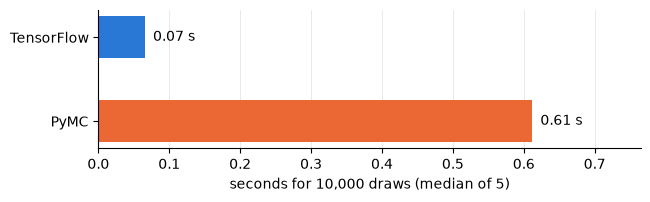

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
labels = list(seconds)
ax.barh(labels, list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is about 10 times faster. The exact times depend on
the computer and its load.

## Two simulated experts

A simulated expert answers with the quantiles that a chosen prior gives.
A real expert gives these quantiles directly.

| Expert | $\phi$ | $\gamma$ | Description |
| :-- | :-- | :-- | :-- |
| A | Uniform(0.7, 1) | Uniform(0.75, 0.95) | most people use TTB |
| B | Uniform(0, 0.3) | Uniform(0.75, 0.95) | most people use WADD |

Each expert gives quantiles of three quantities:

- **TTB, conflict:** "The two rules disagree in 6 questions. In how many does one
  person follow take-the-best?"
- **TTB, agree:** "The two rules agree in 24 questions. In how many does one person
  choose the city of the rules?"
- **TTB majority:** "Of 20 people, how many follow take-the-best in at least 4 of the
  6 conflict questions?"

A participant with at least 4 TTB choices in the 6 conflict questions
has a **TTB majority**.

The expert answers each question with the 10 %, 25 %, 50 %, 75 % and
90 % quantiles. For the 10 % quantile, the question is: "Give a value
that is too low with a probability of 10 %."

On the agree questions, both heuristics choose the same city. This share
therefore tells `elicito` the accuracy $\gamma$. On the conflict
questions, a TTB user makes many TTB choices, and a WADD user makes few.
This share therefore tells `elicito` the share of TTB users $\phi$.

The two quantities of one participant are not sufficient. For one
participant, $z_i$ is 1 with the probability $E[\phi]$. The choices of one
participant therefore depend on $\phi$ only through its mean. Every Beta
prior with this mean gives the same quantiles, also a prior that is
almost flat. The share of TTB majorities describes the **group**. Its
spread depends on the spread of $\phi$.

In [12]:
EXPERTS = {
    "Expert A": {"phi": tfd.Uniform(0.7, 1.0), "gamma": tfd.Uniform(0.75, 0.95)},
    "Expert B": {"phi": tfd.Uniform(0.0, 0.3), "gamma": tfd.Uniform(0.75, 0.95)},
}


def ttb_conflict(yiq: Any) -> Any:
    """Share of TTB choices on the conflict questions"""
    choices = tf.cast(yiq, tf.float32)
    return tf.reduce_mean(tf.boolean_mask(choices, CONFLICT, axis=3), axis=-1)


def ttb_agree(yiq: Any) -> Any:
    """Share of TTB choices on the agree questions"""
    choices = tf.cast(yiq, tf.float32)
    return tf.reduce_mean(tf.boolean_mask(choices, ~CONFLICT, axis=3), axis=-1)


def ttb_majority(yiq: Any) -> Any:
    """Share of participants with at least 4 TTB choices in 6 conflict questions"""
    majority = tf.cast(ttb_conflict(yiq) > 0.5, tf.float32)  # noqa: PLR2004
    return tf.reduce_mean(majority, axis=-1)


PROBS = (0.1, 0.25, 0.5, 0.75, 0.9)
targets = [
    el.quantiles("TTB, conflict", output=ttb_conflict, probs=PROBS),
    el.quantiles("TTB, agree", output=ttb_agree, probs=PROBS),
    el.quantiles("TTB majority", output=ttb_majority, probs=PROBS),
]

In [13]:
fits = {}
for expert, ground_truth in EXPERTS.items():
    eliobj = el.Elicit(model, targets, seeds=(1, 2, 3), epochs=400, verbose=False)
    fits[expert] = eliobj.fit(
        el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)
    )

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

Different priors can give the same quantiles. The learned prior can
therefore differ from the prior of the simulated expert, and the
elicitation is still correct.

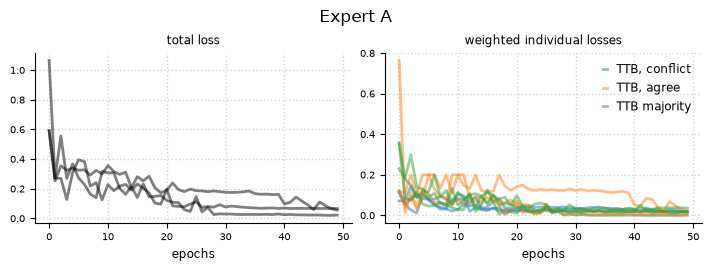

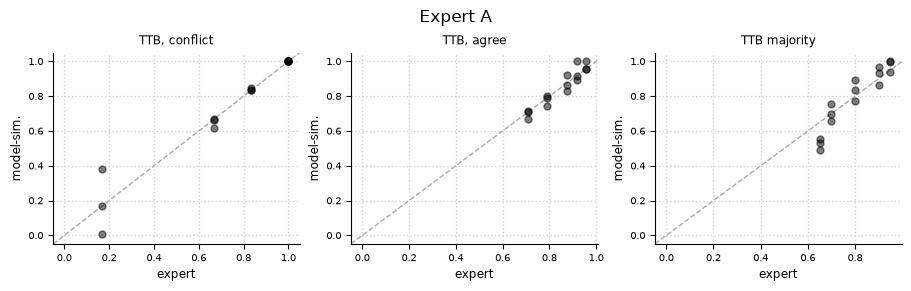

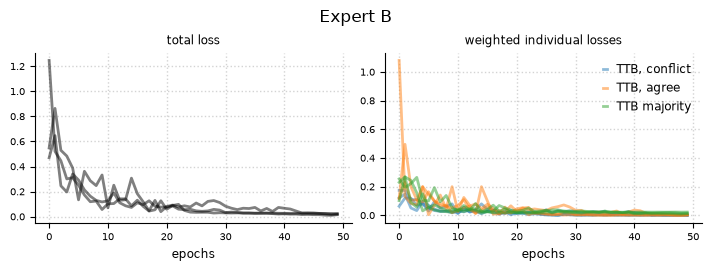

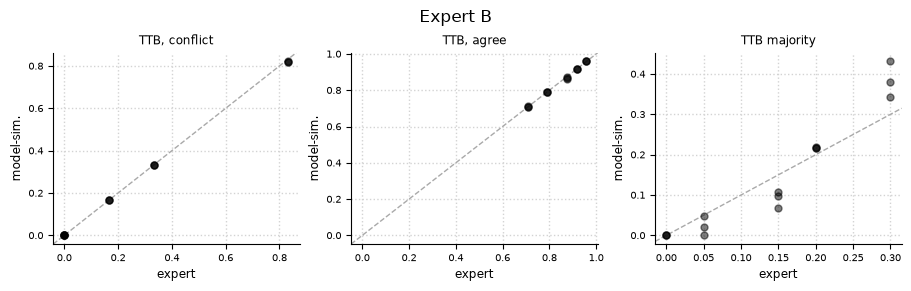

In [14]:
for expert, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()
    fig, _ = fit.plot.elicits(cols=3, figsize=(9, 2.8))
    fig.suptitle(expert)
    plt.show()

For both experts, the elicited quantiles of one participant are near the
diagonal. The quantiles of the TTB majorities are wider than those of the
experts: for expert A, the 10 % quantile is about 0.5 instead of 0.65.
The elicited prior of $\phi$ is therefore wider than the prior of the
expert.

A Uniform prior has two bounds. The search can return them in the wrong
order, for example a lower bound of 0.95 and an upper bound of 0.75. The
samples are then the same, but PyMC needs `lower < upper`. We therefore
sort the bounds of $\gamma$. We use the replication with the lowest loss.

In [15]:
def elicited_prior(fit: Any) -> dict[str, float]:
    """Return the hyperparameters of the best replication, bounds sorted"""
    values = fit.hyperparameters()
    lower, upper = sorted((values["gamma_lower"], values["gamma_upper"]))
    return values | {"gamma_lower": lower, "gamma_upper": upper}


PRIORS = {
    "Book": {"phi_alpha": 1.0, "phi_beta": 1.0, "gamma_lower": 0.5, "gamma_upper": 1.0}
}
PRIORS |= {expert: elicited_prior(fit) for expert, fit in fits.items()}

for label, prior in PRIORS.items():
    print(f"{label:<10}" + "  ".join(f"{k} {v:.2f}" for k, v in prior.items()))

Book      phi_alpha 1.00  phi_beta 1.00  gamma_lower 0.50  gamma_upper 1.00
Expert A  phi_beta 0.58  phi_alpha 3.08  gamma_upper 0.96  gamma_lower 0.74
Expert B  phi_beta 5.11  phi_alpha 0.89  gamma_upper 0.97  gamma_lower 0.72


## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to the data. The book prior,
$\phi \sim \operatorname{Beta}(1, 1)$ and
$\gamma \sim \operatorname{Uniform}(0.5, 1)$, is the reference.

In [16]:
PARAMETERS = ("phi", "gamma")

posteriors, predictives = {}, {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(prior)
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1, progressbar=True)
        pm.sample_posterior_predictive(
            idata, extend_inferencedata=True, random_seed=1, progressbar=False
        )
    posteriors[label] = idata.posterior
    predictives[label] = idata.posterior_predictive

print(f"{'prior':<10}{'parameter':<10}{'mean':>6}{'90 % interval':>16}")
for label, posterior in posteriors.items():
    for name in PARAMETERS:
        values = posterior[name].values.ravel()
        low, high = np.quantile(values, [0.05, 0.95])
        print(
            f"{label:<10}{name:<10}{values.mean():>6.2f}{f'{low:.2f}, {high:.2f}':>16}"
        )

Output()

Output()

Output()

prior     parameter   mean   90 % interval
Book      phi         0.46      0.27, 0.65
Book      gamma       0.80      0.77, 0.83
Expert A  phi         0.53      0.34, 0.71
Expert A  gamma       0.80      0.77, 0.83
Expert B  phi         0.36      0.21, 0.54
Expert B  gamma       0.80      0.77, 0.83


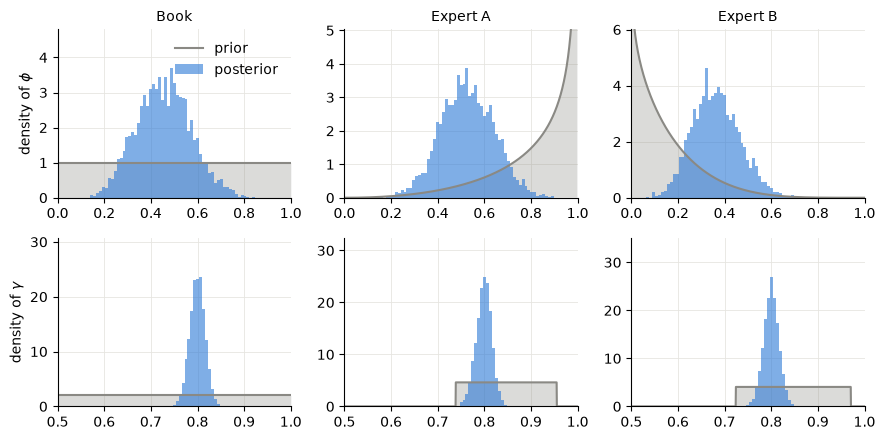

In [17]:
def prior_density(name: str, prior: dict[str, float], grid: Any) -> Any:
    """Density of the prior of phi (Beta) or gamma (Uniform) on the grid"""
    if name == "phi":
        return stats.beta(prior["phi_alpha"], prior["phi_beta"]).pdf(grid)
    lower, upper = prior["gamma_lower"], prior["gamma_upper"]
    return stats.uniform(lower, upper - lower).pdf(grid)


X_RANGE = {"phi": (0.0, 1.0), "gamma": (0.5, 1.0)}
SYMBOL = {"phi": r"$\phi$", "gamma": r"$\gamma$"}

fig, axs = plt.subplots(len(PARAMETERS), len(PRIORS), figsize=(9, 4.5), sharex="row")
for row, name in enumerate(PARAMETERS):
    grid = np.linspace(*X_RANGE[name], 1000)
    for col, (label, prior) in enumerate(PRIORS.items()):
        ax = axs[row, col]
        density = prior_density(name, prior, grid)
        ax.fill_between(grid, density, color=GREY, alpha=0.3, lw=0)
        ax.plot(grid, density, color=GREY, lw=1.5, label="prior")
        heights, *_ = ax.hist(
            posteriors[label][name].values.ravel(),
            bins=np.linspace(*X_RANGE[name], 80),
            density=True,
            histtype="stepfilled",
            color=BLUE,
            alpha=0.6,
            label="posterior",
        )
        # a Beta density with a parameter below 1 is infinite at the bound:
        # scale the axis to the posterior
        ax.set(xlim=X_RANGE[name], ylim=(0, 1.3 * heights.max()))
        if row == 0:
            ax.set_title(label)
        if col == 0:
            ax.set_ylabel(f"density of {SYMBOL[name]}")
axs[0, 0].legend()
fig.tight_layout()
plt.show()

- **Accuracy $\gamma$.** All three posteriors have the mean 0.80 and the
  90 % interval 0.77 to 0.83. The 600 choices dominate the prior, and
  0.80 is inside the bounds of all three priors.
- **Share of TTB users $\phi$.** The posterior means are 0.46 (book),
  0.53 (expert A) and 0.36 (expert B). Each expert moves the posterior
  by about 0.1 in the direction of the expert.

Each axis shows the posterior in full. The elicited Beta priors of $\phi$
have a parameter below 1, so their density is infinite at a bound of the
axis.

## How strong are the elicited priors?

The elicited priors of $\phi$ have the mean of the experts:
3.08 / 3.66 = 0.84 for expert A, and 0.89 / 6.00 = 0.15 for expert B. As
a rule, a $\operatorname{Beta}(\alpha, \beta)$ prior counts like
$\alpha + \beta$ participants. Here this is 3.7 and 6.0 participants,
against the 20 participants of the data. The data therefore dominate.

A Beta prior with the mean and the standard deviation of
$\operatorname{Uniform}(0.7, 1)$ counts like 16 participants. The
elicited prior is weaker than the prior of the expert. This agrees with
the wide quantiles of the TTB majorities in the elicitation check.

## Who uses TTB?

The posterior also gives, for each participant, the probability that the
participant uses TTB: the posterior mean of $z_i$. The figure shows it for
each prior, with the participants in the order of the first figure.

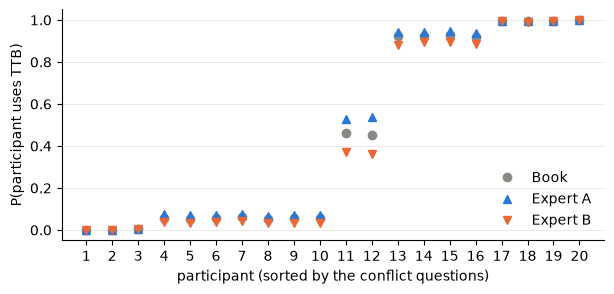

In [18]:
fig, ax = plt.subplots(figsize=(7, 3))
for (label, posterior), color, marker in zip(
    posteriors.items(), (GREY, BLUE, ORANGE), ("o", "^", "v")
):
    p_ttb = posterior["zi"].mean(dim=("chain", "draw")).values
    ax.plot(participants, p_ttb[order], marker, color=color, label=label)
ax.set(
    xlabel="participant (sorted by the conflict questions)",
    ylabel="P(participant uses TTB)",
    xticks=participants,
    ylim=(-0.05, 1.05),
)
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right")
plt.show()

The data classify most participants clearly. For participants 1 to 10,
the probability of TTB is below 0.1. For participants 13 to 20, it is
above 0.9. Only participants 11 and 12, with 3 TTB choices in 6 conflict
questions, stay open: 0.36 to 0.54. There, the prior of $\phi$ decides.
Expert A gives the highest value, expert B the lowest.

## Does the model fit the data?

A posterior predictive check simulates new data from the fitted model,
once for each posterior draw. The figure repeats the first figure, with
one panel for each prior.

The dots are the observed shares of TTB choices. A line is the 90 %
interval of the simulated shares of one participant.

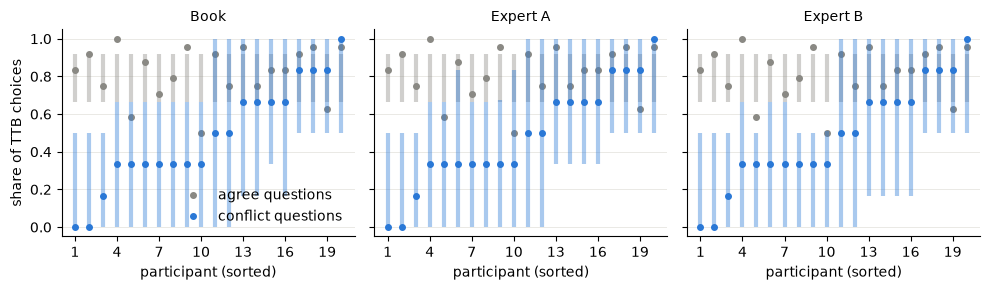

In [19]:
fig, axs = plt.subplots(1, len(PRIORS), figsize=(10, 3), sharey=True)
for ax, (label, predictive) in zip(axs, predictives.items()):
    y_rep = predictive["yiq"].values.reshape(-1, ns, nq)
    for share_obs, questions, color, name in (
        (ttb_agree_obs, ~CONFLICT, GREY, "agree"),
        (ttb_conflict_obs, CONFLICT, BLUE, "conflict"),
    ):
        share_rep = y_rep[:, :, questions].mean(axis=-1)[:, order]
        low, high = np.quantile(share_rep, [0.05, 0.95], axis=0)
        ax.vlines(participants, low, high, color=color, lw=3, alpha=0.4)
        ax.plot(
            participants,
            share_obs[order],
            "o",
            color=color,
            ms=4,
            label=f"{name} questions",
        )
    ax.set(
        title=label,
        xlabel="participant (sorted)",
        xticks=participants[::3],
        ylim=(-0.05, 1.05),
    )
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("share of TTB choices")
axs[0].legend(loc="lower right")
fig.tight_layout()
plt.show()

On the conflict questions, all observed shares are inside the 90 %
intervals, for all three priors. On the agree questions, participants 5,
10 and 19 make fewer TTB choices than the intervals allow: 0.58, 0.50 and
0.62. The model gives all participants the same accuracy $\gamma$, so it
cannot describe a participant with a low accuracy. The prior does not
change this.

## Takeaways

- **Translation.** One call translates the PyMC model. The largest KS
  distance of the three outputs is 0.021.
- **Speed.** The translated model is about 10 times faster than PyMC.
- **Elicitation.** Check the elicited quantiles against the quantiles of
  the expert. Different priors can give the same quantiles.
- **Choice of targets.** A quantity of one participant gives only the
  mean of a group-level parameter such as $\phi$. To elicit the
  uncertainty, ask also for a quantity of the group.
- **Prior strength.** Compare the elicited prior with the data: a Beta
  prior counts like $\alpha + \beta$ observations.
- **Posterior predictive check.** One accuracy for all participants does
  not fit three of the 20 participants, with any prior.

## Appendix

The PyMC3 model comes from the notebook
[HeuristicDecisionMaking.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/HeuristicDecisionMaking.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [20]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.